Use different voting mechanism and Apply AdaBoost (Adaptive Boosting), Gradient Tree Boosting (GBM), XGBoost classification on Iris dataset and compare the performance of three models using different evaluation measures. Dataset Link: https://www.kaggle.com/datasets/uciml/iris

In [19]:
# !pip install pandas numpy matplotlib seaborn scikit-learn xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

from xgboost import XGBClassifier

In [3]:
df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

Dataset Shape: (150, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB

Statistical Description:
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.80000

In [5]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [6]:
if 'Id' in df.columns:
    df.drop('Id', axis=1, inplace=True)

df.head()

C:\Users\Roshani Bhalchim\AppData\Local\Temp\ipykernel_46604\3194222052.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Id', axis=1, inplace=True)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [7]:
X = df.drop('Species', axis=1)

y = df['Species']

le = LabelEncoder()

y = le.fit_transform(y)

print("Target Classes:", le.classes_)

Target Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [9]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)

ada.fit(X_train, y_train)

y_pred_ada = ada.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))

AdaBoost Accuracy: 0.9333333333333333


In [10]:
gbm = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gbm.fit(X_train, y_train)

y_pred_gbm = gbm.predict(X_test)

print("GBM Accuracy:", accuracy_score(y_test, y_pred_gbm))

GBM Accuracy: 0.9666666666666667


In [11]:
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9333333333333333


In [12]:
models = {
    'AdaBoost': y_pred_ada,
    'GBM': y_pred_gbm,
    'XGBoost': y_pred_xgb
}

results = []

for name, pred in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='weighted'),
        'Recall': recall_score(y_test, pred, average='weighted'),
        'F1 Score': f1_score(y_test, pred, average='weighted')
    })

results_df = pd.DataFrame(results)

print(results_df)

      Model  Accuracy  Precision    Recall  F1 Score
0  AdaBoost  0.933333   0.933333  0.933333  0.933333
1       GBM  0.966667   0.969697  0.966667  0.966583
2   XGBoost  0.933333   0.933333  0.933333  0.933333


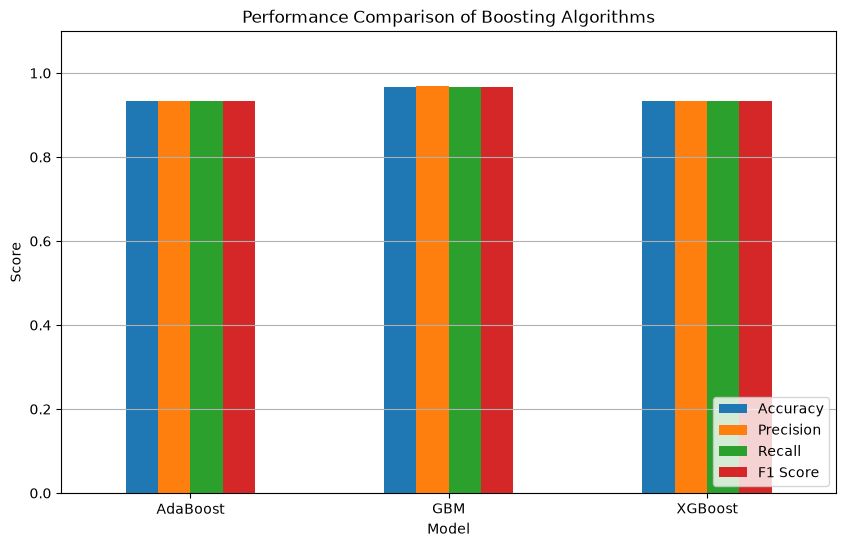

In [13]:
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Performance Comparison of Boosting Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

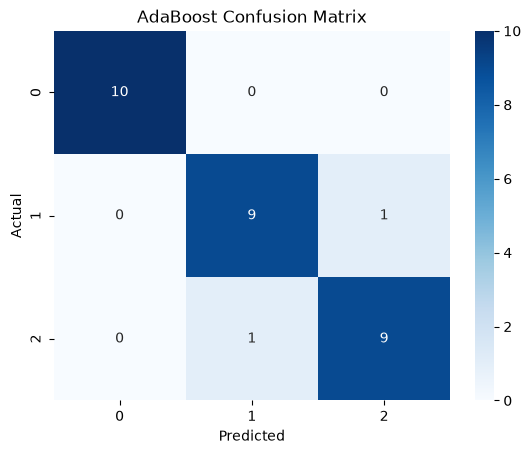

In [14]:
cm = confusion_matrix(y_test, y_pred_ada)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("AdaBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

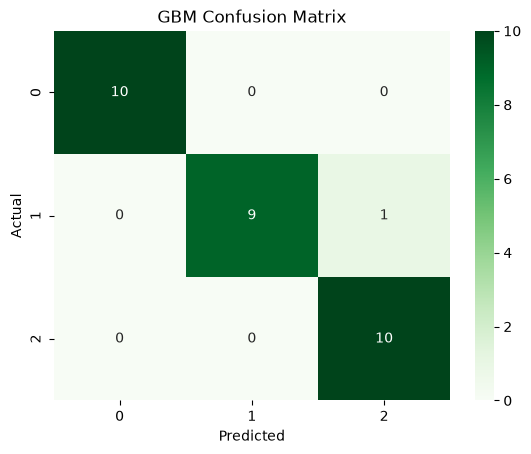

In [15]:
cm = confusion_matrix(y_test, y_pred_gbm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')

plt.title("GBM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

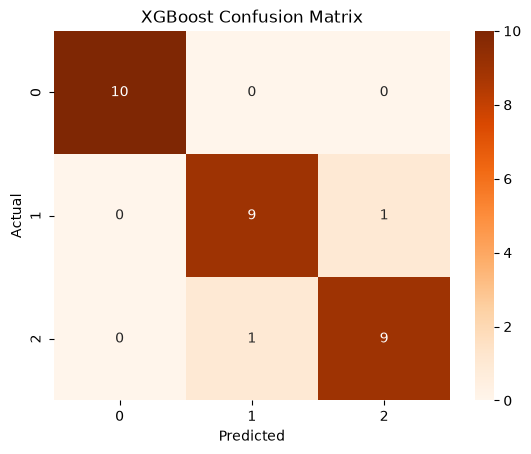

In [16]:
cm = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
print("ADA BOOST CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_ada, target_names=le.classes_))

print("\nGBM CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_gbm, target_names=le.classes_))

print("\nXGBOOST CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_))

ADA BOOST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30


GBM CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30


XGBOOST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00  

In [18]:
best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model             GBM
Accuracy     0.966667
Precision    0.969697
Recall       0.966667
F1 Score     0.966583
Name: 1, dtype: object
